In [18]:
import pandas as pd
import os
from tabulate import tabulate 
from tabulate import tabulate 
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [19]:
archivo = os.path.join("..", "Data", "Bd.csv")

In [20]:
df = pd.read_csv(archivo)
df["Total habitantes"] = pd.to_numeric(
            df["Total habitantes"].astype(str)
            .str.replace('.', '', regex=False)
            .str.replace(',', '', regex=False), 
            errors='coerce'
        )
df["Varon/Masculino"] = pd.to_numeric(
            df["Varon/Masculino"].astype(str)
            .str.replace('.', '', regex=False)
            .str.replace(',', '', regex=False), 
            errors='coerce'
        )
df

,Codigo,Nombre,Tipo de jurisdicción,Provincia/estado,Casa,Rancho,Departamento,Otro tipo de vivienda,Total de viviendas,Varon/Masculino,Mujer/Femenino,Total habitantes
0,6007,Adolfo Alsina,Partido,Buenos Aires,"6,649",46,428,457,"7,580",8634,"8,710",17344
1,6014,Adolfo Gonzales Chaves,Partido,Buenos Aires,"4,814",18,233,251,"5,316",6281,"6,566",12847
2,6021,Alberti,Partido,Buenos Aires,"4,539",40,214,279,"5,072",6255,"6,651",12906
3,6028,Almirante Brown,Partido,Buenos Aires,"157,391",741,"19,972","21,559","199,663",281639,"301,570",583209
4,6035,Avellaneda,Partido,Buenos Aires,"88,382",460,"41,789","43,655","174,286",173001,"193,116",366117
...,...,...,...,...,...,...,...,...,...,...,...,...
154,78,Santa Cruz,Provincia,Argentina,"94,967",792,"18,914","3,374","118,047",165865,"169,812",335677
155,82,Santa Fe,Provincia,Argentina,"1,019,740","11,281","224,927","17,512","1,273,460",1695274,"1,823,785",3519059
156,86,Santiago del Estero,Provincia,Argentina,"277,047","15,508","13,964","4,842","311,361",519158,"538,594",1057752
157,90,Tucumán,Provincia,Argentina,"416,796","3,925","55,506","17,567","493,794",836700,"890,637",1727337


In [22]:
def ver_informacion_general(df):
    """
    Opción 2: Muestra las primeras filas, nombres, tipos y nulos por columna.
    Registra la acción en el log y devuelve el DataFrame.
    """
    print("📊 INFORMACIÓN TIPOS DE DATOS")
    print("\n2. Tipos de datos y columnas:")
    print(df.dtypes)
print(ver_informacion_general(df))

📊 INFORMACIÓN TIPOS DE DATOS

2. Tipos de datos y columnas:
Codigo                   int64
Nombre                     str
Tipo de jurisdicción       str
Provincia/estado           str
Casa                       str
Rancho                     str
Departamento               str
Otro tipo de vivienda      str
Total de viviendas         str
Varon/Masculino          int64
Mujer/Femenino             str
Total habitantes         int64
dtype: object
None


In [59]:
#Total de habitantes por partido
def TotalHabitantesPartido(df):
    """
    Filtrar por Partido, agrupar por Nombre y sumar los habitantes
    """
    try:
        resultado = (
            df.query("`Tipo de jurisdicción` == 'Partido'")
            .groupby("Nombre")["Total habitantes"]
            .sum()
            .reset_index()
            .sort_values(by="Total habitantes", ascending=False)
        )
         # Imprimir usando tabulate con un diseño estético de grilla y sin mostrar el índice numérico
        print(tabulate(
                    resultado, 
                    headers=['Partido', 'Total Habitantes'], 
                    tablefmt='fancy_grid', 
                    showindex=False
                ))
    except Exception as e:
        print(f"[Error en TotalHabitantesPartido]: {e}")

print(TotalHabitantesPartido(df))

╒════════════════════════════════════╤════════════════════╕
│ Partido                            │ Total Habitantes   │
╞════════════════════════════════════╪════════════════════╡
│ San Vicente                        │ 97.929             │
├────────────────────────────────────┼────────────────────┤
│ Castelli                           │ 9.551              │
├────────────────────────────────────┼────────────────────┤
│ Salliqueló                         │ 9.344              │
├────────────────────────────────────┼────────────────────┤
│ Tres Lomas                         │ 9.090              │
├────────────────────────────────────┼────────────────────┤
│ San Cayetano                       │ 8.918              │
├────────────────────────────────────┼────────────────────┤
│ Monte Hermoso                      │ 8.444              │
├────────────────────────────────────┼────────────────────┤
│ La Plata                           │ 756.074            │
├────────────────────────────────────┼──

In [ ]:


import pandas as pd
 # Asegúrate de tenerlo instalado: pip install tabulate

def TotalHabitantesPartido(df):
    """
    Filtra por Partido, agrupa por Nombre, suma los habitantes,
    y muestra la tabla completa con un formato visual ordenado.
    """
    try:
        resultado = (
            df.query("`Tipo de jurisdicción` == 'Partido'")
            .groupby("Nombre")["Total habitantes"]
            .sum()
            .reset_index()
            .sort_values(by="Total habitantes", ascending=False)
        )
        resultado["Total habitantes"] = resultado["Total habitantes"].apply(
            lambda x: f"{int(x):,}".replace(",", ".") if pd.notnull(x) else ""
        )
        # Imprimir usando tabulate con un diseño estético de grilla y sin mostrar el índice numérico
        print(tabulate(
            resultado, 
            headers=['Partido', 'Total Habitantes'], 
            tablefmt='fancy_grid', 
            showindex=False
        ))
        
    except Exception as e:
        print(f"[Error en TotalHabitantesPartido]: {e}")

# Llamada a la función
TotalHabitantesPartido(df)

╒════════════════════════════════════╤════════════════════╕
│ Partido                            │ Total Habitantes   │
╞════════════════════════════════════╪════════════════════╡
│ La Matanza                         │ 1.837.168          │
├────────────────────────────────────┼────────────────────┤
│ La Plata                           │ 756.074            │
├────────────────────────────────────┼────────────────────┤
│ Lomas de Zamora                    │ 685.644            │
├────────────────────────────────────┼────────────────────┤
│ General Pueyrredón                 │ 660.569            │
├────────────────────────────────────┼────────────────────┤
│ Quilmes                            │ 631.774            │
├────────────────────────────────────┼────────────────────┤
│ Almirante Brown                    │ 583.209            │
├────────────────────────────────────┼────────────────────┤
│ Merlo                              │ 581.484            │
├────────────────────────────────────┼──

In [69]:
def Habitantes_Por_Partido(df,Partido):
    """
    Filtra por Partido,Toma como parametro el nombre del partido, agrupa por Nombre, suma los habitantes,
    y muestra la tabla completa con un formato visual ordenado.
    """
    try:
        resultado = (
            df.query("`Tipo de jurisdicción` == 'Partido' and Nombre == @Partido")
            .groupby("Nombre")["Total habitantes"]
            .sum()
            .reset_index()
            .sort_values(by="Total habitantes", ascending=False)
        )
        resultado["Total habitantes"] = resultado["Total habitantes"].apply(
                    lambda x: f"{int(x):,}".replace(",", ".") if pd.notnull(x) else ""
                )
        # Imprimir usando tabulate con un diseño estético de grilla y sin mostrar el índice numérico
        print(tabulate(
            resultado, 
            headers=['Partido', 'Total Habitantes'], 
            tablefmt='fancy_grid', 
            showindex=False
        ))
        
    except Exception as e:
        print(f"[Error en TotalHabitantesPartido]: {e}")

# Llamada a la función
Habitantes_Por_Partido(df,"Tres de Febrero")

╒═════════════════╤════════════════════╕
│ Partido         │   Total Habitantes │
╞═════════════════╪════════════════════╡
│ Tres de Febrero │            362.319 │
╘═════════════════╧════════════════════╛


In [17]:
import pandas as pd
from tabulate import tabulate


def EstadisticasHabitantesPartido(df):
  """
    Filtra por Partido, agrupa por Nombre para sumar los habitantes de cada partido,
    calcula cantidad, promedio, mínimo, máximo y mediana, y muestra la tabla ordenada.
    """
  try:
    datos = df.copy()
    datos["Total habitantes"] = pd.to_numeric(
        datos["Total habitantes"]
        .astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.replace(".", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce",
    )

    # Agrupamos por Nombre igual que en tu función modelo para obtener el total por Partido
    por_partido = (
        datos.query("`Tipo de jurisdicción` == 'Partido'")
        .groupby("Nombre")["Total habitantes"]
        .sum()
    )

    cantidad = int(por_partido.count())
    promedio = por_partido.mean()
    minimo = por_partido.min()
    maximo = por_partido.max()
    mediana = por_partido.median()

    def formatear(valor, decimales=False):
      if pd.isnull(valor):
        return ""
      if decimales:
        return (
            f"{valor:,.2f}".replace(",", "X")
            .replace(".", ",")
            .replace("X", ".")
        )
      return f"{int(round(valor)):,}".replace(",", ".")

    resultado = pd.DataFrame({
        "Métrica": [
            "Cantidad de Partidos",
            "Promedio de Habitantes",
            "Mínimo de Habitantes",
            "Máximo de Habitantes",
            "Mediana de Habitantes",
        ],
        "Valor": [
            formatear(cantidad),
            formatear(promedio, decimales=False),
            formatear(minimo),
            formatear(maximo),
            formatear(mediana, decimales=False),
        ],
    })

    print(
        tabulate(
            resultado.values.tolist(),
            headers=["Métrica", "Valor"],
            tablefmt="pretty",
            disable_numparse=True,
            showindex=False,
        )
    )
    return resultado

  except Exception as e:
    print(f"[Error en EstadisticasHabitantesPartido]: {e}")

EstadisticasHabitantesPartido(df)

+------------------------+-----------+
|        Métrica         |   Valor   |
+------------------------+-----------+
|  Cantidad de Partidos  |    135    |
| Promedio de Habitantes |  128.955  |
|  Mínimo de Habitantes  |   2.528   |
|  Máximo de Habitantes  | 1.837.168 |
| Mediana de Habitantes  |  39.223   |
+------------------------+-----------+


,Métrica,Valor
0,Cantidad de Partidos,135
1,Promedio de Habitantes,128.955
2,Mínimo de Habitantes,2.528
3,Máximo de Habitantes,1.837.168
4,Mediana de Habitantes,39.223


In [6]:
import pandas as pd
from tabulate import tabulate  # Asegúrate de tenerlo instalado: pip install tabulate

def TotalVaronPartido(df):
    """
    Filtra por Partido, agrupa por Nombre, suma los habitantes,
    y muestra la tabla completa con un formato visual ordenado.
    """
    try:
        resultado = (
            df.query("`Tipo de jurisdicción` == 'Partido'")
            .groupby("Nombre")["Varon/Masculino"]
            .sum()
            .reset_index()
            .sort_values(by="Varon/Masculino", ascending=False)
        )
        resultado["Varon/Masculino"] = resultado["Varon/Masculino"].apply(
            lambda x: f"{int(x):,}".replace(",", ".") if pd.notnull(x) else ""
        )
        # Imprimir usando tabulate con un diseño estético de grilla y sin mostrar el índice numérico
        print(tabulate(
            resultado, 
            headers=['Partido', 'Varon/Masculino'], 
            tablefmt='fancy_grid', 
            showindex=False
        ))
        
    except Exception as e:
        print(f"[Error en TotalVaronPartido]: {e}")

# Llamada a la función
TotalVaronPartido(df)

╒════════════════════════════════════╤═══════════════════╕
│ Partido                            │   Varon/Masculino │
╞════════════════════════════════════╪═══════════════════╡
│ La Matanza                         │           884.998 │
├────────────────────────────────────┼───────────────────┤
│ La Plata                           │           360.198 │
├────────────────────────────────────┼───────────────────┤
│ Lomas de Zamora                    │           329.533 │
├────────────────────────────────────┼───────────────────┤
│ General Pueyrredón                 │           312.786 │
├────────────────────────────────────┼───────────────────┤
│ Quilmes                            │           303.499 │
├────────────────────────────────────┼───────────────────┤
│ Merlo                              │           282.086 │
├────────────────────────────────────┼───────────────────┤
│ Almirante Brown                    │           281.639 │
├────────────────────────────────────┼──────────────────

In [7]:
def Cantidad_Partidos_Unicos(df):
  """
    Filtra por Tipo de jurisdicción == 'Partido', cuenta la cantidad única de registros
    y muestra el resultado con un formato visual ordenado.
    """
  try:
    cantidad_unica = df.query("`Tipo de jurisdicción` in ['Partido']")[
        "Nombre"
    ].nunique()

    resultado = pd.DataFrame({
        "Tipo de jurisdicción": ["Partido",],
        "Cantidad Única": [f"{int(cantidad_unica):,}".replace(",", ".")],
    })

    # .values.tolist() satisface el tipado estricto de tabulate
    print(
        tabulate(
            resultado.values.tolist(),
            headers=["Tipo de jurisdicción", "Cantidad Única"],
            tablefmt="pretty",
            disable_numparse=True,
            showindex=False,
        )
    )
    return resultado
  except Exception as e:
    print(f"[Error en Cantidad_Partidos_Unicos]: {e}")

Cantidad_Partidos_Unicos(df)

+----------------------+----------------+
| Tipo de jurisdicción | Cantidad Única |
+----------------------+----------------+
|       Partido        |      135       |
+----------------------+----------------+


,Tipo de jurisdicción,Cantidad Única
0,Partido,135


+-------------------+------------+------------+
|      Género       |  Cantidad  | Porcentaje |
+-------------------+------------+------------+
| Varón / Masculino | 8.393.419  |   48,21%   |
| Mujer / Femenino  | 9.015.487  |   51,79%   |
|       Total       | 17.408.906 |  100,00%   |
+-------------------+------------+------------+


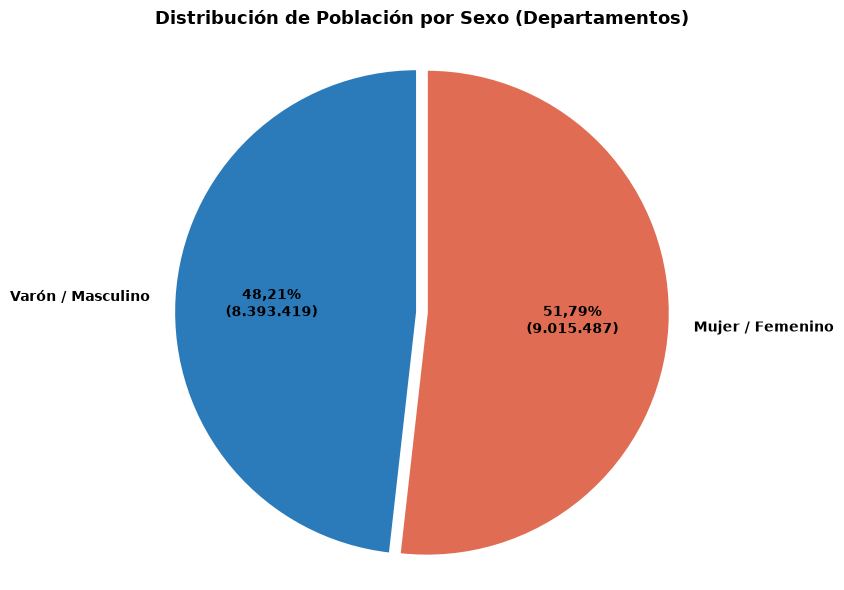

,Género,Cantidad,Porcentaje
0,Varón / Masculino,8.393.419,"48,21%"
1,Mujer / Femenino,9.015.487,"51,79%"
2,Total,17.408.906,"100,00%"


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd
from tabulate import tabulate


def GraficarDistribucionSexo(df):
    try:
        datos = df.query("`Tipo de jurisdicción` == 'Partido'").copy()

        for col in ["Varon/Masculino", "Mujer/Femenino"]:
            datos[col] = pd.to_numeric(
                datos[col].astype(str)
                .str.replace(r'\.0$', '', regex=True)
                .str.replace('.', '', regex=False)
                .str.replace(',', '', regex=False),
                errors='coerce'
            )

        total_varones = int(datos["Varon/Masculino"].sum())
        total_mujeres = int(datos["Mujer/Femenino"].sum())
        total_general = total_varones + total_mujeres

        if total_general == 0:
            print("No hay datos numéricos válidos para graficar en Departamentos.")
            return None

        pct_varones = (total_varones / total_general) * 100
        pct_mujeres = (total_mujeres / total_general) * 100

        resultado = pd.DataFrame({
            "Género": ["Varón / Masculino", "Mujer / Femenino", "Total"],
            "Cantidad": [
                f"{total_varones:,}".replace(",", "."),
                f"{total_mujeres:,}".replace(",", "."),
                f"{total_general:,}".replace(",", ".")
            ],
            "Porcentaje": [
                f"{pct_varones:.2f}%".replace(".", ","),
                f"{pct_mujeres:.2f}%".replace(".", ","),
                "100,00%"
            ]
        })

        print(tabulate(
            resultado.values.tolist(),
            headers=["Género", "Cantidad", "Porcentaje"],
            tablefmt="pretty",
            disable_numparse=True,
            showindex=False
        ))

        etiquetas = ["Varón / Masculino", "Mujer / Femenino"]
        valores = [total_varones, total_mujeres]
        colores = ["#2b7bba", "#e06d53"]

        def mostrar_cantidad_y_porcentaje(pct):
            absoluto = int(round((pct / 100.0) * total_general))
            cant_formateada = f"{absoluto:,}".replace(",", ".")
            pct_formateado = f"{pct:.2f}%".replace(".", ",")
            return f"{pct_formateado}\n({cant_formateada})"

        fig, ax = plt.subplots(figsize=(8, 6))
        ax.pie(
            valores,
            labels=etiquetas,
            colors=colores,
            autopct=mostrar_cantidad_y_porcentaje,
            startangle=90,
            explode=(0.02, 0.02),
            textprops={"fontsize": 10, "fontweight": "bold"},
            wedgeprops={"edgecolor": "white", "linewidth": 1.5}
        )

        ax.set_title("Distribución de Población por Sexo (Departamentos)", fontsize=13, fontweight="bold", pad=15)
        ax.axis("equal")
        plt.tight_layout()

        # Fuerza a Jupyter a mostrar el gráfico al instante
        display(fig)
        plt.close(fig)

        return resultado

    except Exception as e:
        print(f"[Error en GraficarDistribucionSexoDepartamento]: {e}")


# Asegurate de llamar a la función:
GraficarDistribucionSexo(df)